# Auto-ARIMA for Time Series Forecasting

Auto-ARIMA automates the search for ARIMA/SARIMA orders. This notebook demonstrates non-seasonal and seasonal Auto-ARIMA using `pmdarima`, with chronological validation, metrics, residual diagnostics, and future forecasting.

Install: `pip install numpy pandas matplotlib pmdarima scikit-learn statsmodels`

The dataset is synthetic. Auto-ARIMA automates order selection; it does not guarantee the best forecast. Validate on unseen data.

## 1. Import libraries

In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
np.random.seed(42)

## 2. Create synthetic monthly demand data

The series contains an upward trend, annual seasonality, and random noise. The seasonal period is 12.

In [4]:
dates = pd.date_range("2015-01-01", periods=120, freq="MS")
t = np.arange(len(dates))
month = dates.month
season_pattern = np.array([-12, -8, -4, 1, 7, 12, 17, 13, 6, -2, 8, 20])
demand = 150 + 0.7*t + season_pattern[month-1] + np.random.normal(0, 7, len(dates))
df = pd.DataFrame({"demand": demand}, index=dates)
df.index.name = "date"
df.head()

,demand
date,
2015-01-01,141.476999
2015-02-01,141.732150
2015-03-01,151.933820
2015-04-01,163.761209
2015-05-01,158.160926


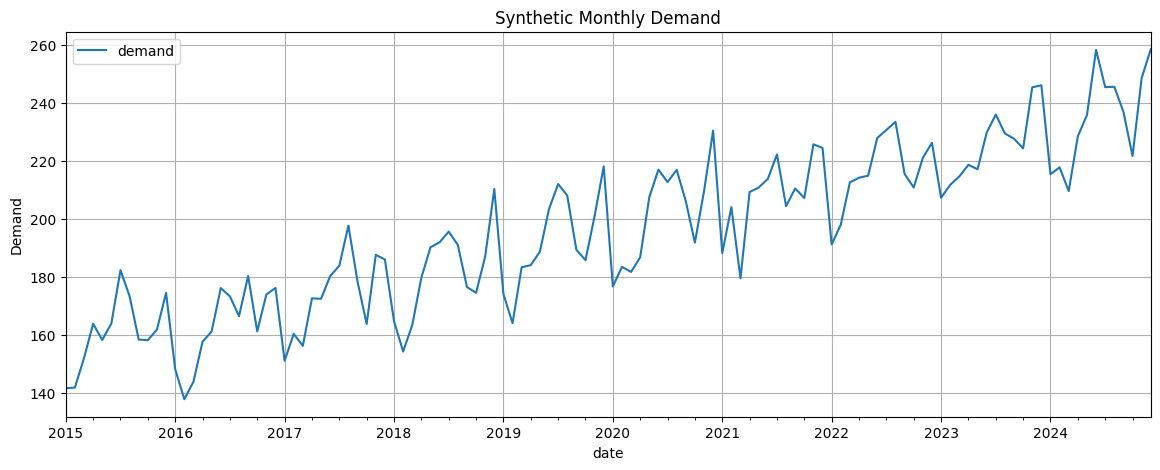

In [5]:
df.plot(figsize=(14,5), title="Synthetic Monthly Demand", grid=True)
plt.ylabel("Demand")
plt.show()

## 3. Chronological train-validation-test split

We use 70% for training, 15% for validation, and 15% for testing. Do not shuffle time-series observations. Training fits the model, validation supports model selection, and test is reserved for final evaluation.

84 18 18


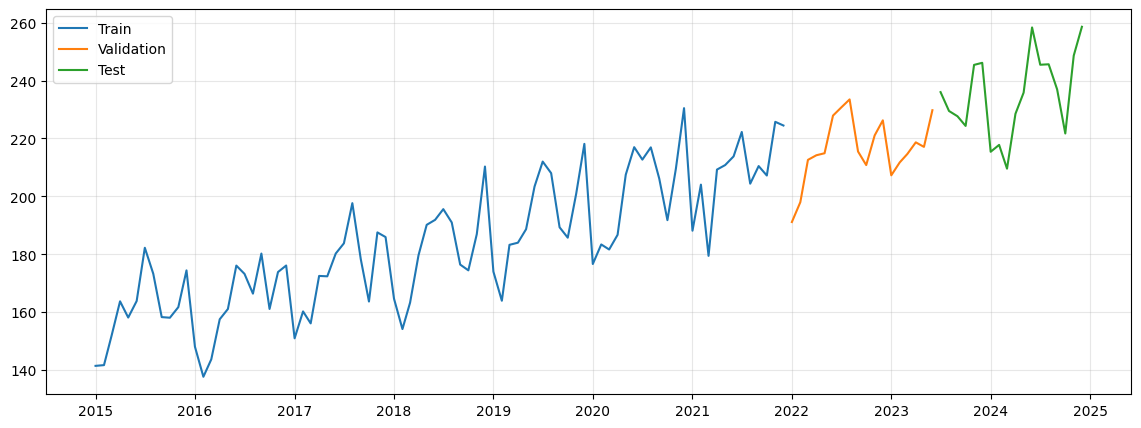

In [6]:
n = len(df)
i = int(n*0.70)
j = int(n*0.85)
train, validation, test = df.iloc[:i], df.iloc[i:j], df.iloc[j:]
y_train, y_val, y_test = train.demand, validation.demand, test.demand
print(len(train), len(validation), len(test))
plt.figure(figsize=(14,5))
plt.plot(y_train, label="Train")
plt.plot(y_val, label="Validation")
plt.plot(y_test, label="Test")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 4. Auto-ARIMA concepts

ARIMA is represented as `ARIMA(p,d,q)`:
- `p`: autoregressive order (past observations).
- `d`: non-seasonal differencing order.
- `q`: moving-average order (past forecast errors).

Seasonal ARIMA is `SARIMA(p,d,q) × (P,D,Q,m)`:
- `P`: seasonal AR order.
- `D`: seasonal differencing order.
- `Q`: seasonal MA order.
- `m`: observations per seasonal cycle (12 for monthly annual seasonality).

Auto-ARIMA searches candidate orders within configured bounds and ranks them using an information criterion such as AIC or BIC. AIC is `2k - 2 log(L)`, where `k` is the number of estimated parameters and `L` is the maximized likelihood. Lower AIC is preferred among comparable candidates, but AIC is not a substitute for out-of-sample validation.

## 5. Non-seasonal Auto-ARIMA

With `seasonal=False`, the search is restricted to non-seasonal ARIMA orders. `d=None` lets the procedure estimate differencing; `stepwise=True` reduces the number of candidate fits.

In [7]:
nonseasonal_model = auto_arima(
    y_train, seasonal=False,
    start_p=0, start_q=0, max_p=4, max_q=4,
    d=None, max_d=2,
    information_criterion="aic",
    stepwise=True, trace=True,
    error_action="ignore", suppress_warnings=True,
    with_intercept="auto"
)
print(nonseasonal_model.summary())
print("Selected order:", nonseasonal_model.order)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=687.248, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=685.263, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.02 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=685.624, Time=0.00 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=681.554, Time=0.02 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   : AIC=678.867, Time=0.02 sec
 ARIMA(4,1,0)(0,0,0)[0] intercept   : AIC=678.315, Time=0.02 sec
 ARIMA(4,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.06 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.05 sec
 ARIMA(4,1,0)(0,0,0)[0]             : AIC=677.983, Time=0.01 sec
 ARIMA(3,1,0)(0,0,0)[0]             : AIC=678.145, Time=0.01 sec
 ARIMA(4,1,1)(0,0,0)[0]             : AIC=675.578, Time=0.03 sec
 ARIMA(3,1,1)(0,0,0)[0]             : AIC=673.583, Time=0.02 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=671.805, Time=0.01 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=671.409, Time=0.0

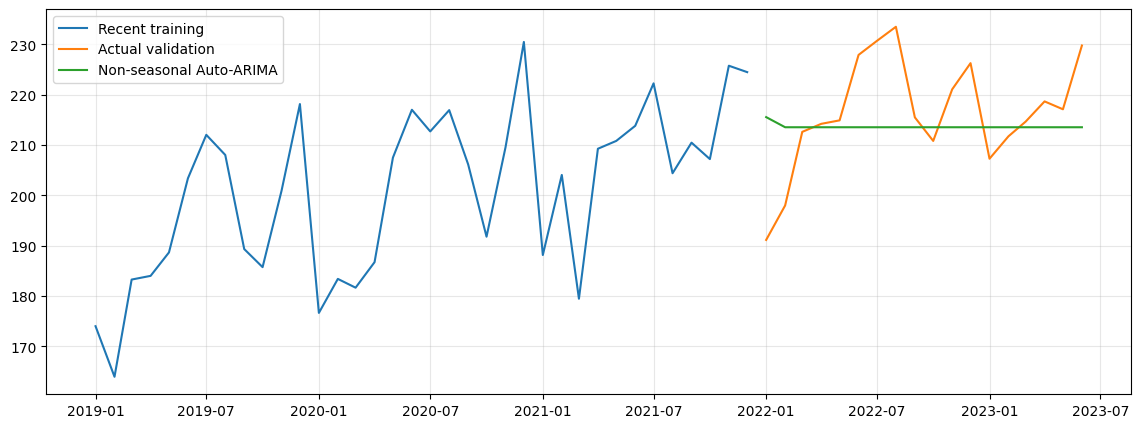

In [8]:
nonseasonal_pred = pd.Series(
    nonseasonal_model.predict(n_periods=len(validation)),
    index=validation.index
)
plt.figure(figsize=(14,5))
plt.plot(y_train.tail(36), label="Recent training")
plt.plot(y_val, label="Actual validation")
plt.plot(nonseasonal_pred, label="Non-seasonal Auto-ARIMA")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 6. Seasonal Auto-ARIMA

For monthly data with annual seasonality, set `seasonal=True, m=12`. The model search includes non-seasonal and seasonal orders. The maximum orders below constrain computation; selected orders are data-dependent.

In [9]:
seasonal_model = auto_arima(
    y_train, seasonal=True, m=12,
    start_p=0, start_q=0, max_p=3, max_q=3,
    start_P=0, start_Q=0, max_P=2, max_Q=2,
    d=None, D=None, max_d=2, max_D=1,
    information_criterion="aic",
    stepwise=True, trace=True,
    error_action="ignore", suppress_warnings=True,
    with_intercept="auto"
)
print(seasonal_model.summary())
print("Selected order:", seasonal_model.order)
print("Seasonal order:", seasonal_model.seasonal_order)

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[12] intercept   : AIC=687.248, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[12] intercept   : AIC=643.177, Time=0.04 sec
 ARIMA(0,1,1)(0,0,1)[12] intercept   : AIC=inf, Time=0.08 sec
 ARIMA(0,1,0)(0,0,0)[12]             : AIC=685.624, Time=0.00 sec
 ARIMA(1,1,0)(0,0,0)[12] intercept   : AIC=685.263, Time=0.01 sec
 ARIMA(1,1,0)(2,0,0)[12] intercept   : AIC=637.354, Time=0.10 sec
 ARIMA(1,1,0)(2,0,1)[12] intercept   : AIC=inf, Time=0.28 sec
 ARIMA(1,1,0)(1,0,1)[12] intercept   : AIC=inf, Time=0.14 sec
 ARIMA(0,1,0)(2,0,0)[12] intercept   : AIC=656.384, Time=0.06 sec
 ARIMA(2,1,0)(2,0,0)[12] intercept   : AIC=inf, Time=0.11 sec
 ARIMA(1,1,1)(2,0,0)[12] intercept   : AIC=inf, Time=0.32 sec
 ARIMA(0,1,1)(2,0,0)[12] intercept   : AIC=inf, Time=0.19 sec
 ARIMA(2,1,1)(2,0,0)[12] intercept   : AIC=inf, Time=0.33 sec
 ARIMA(1,1,0)(2,0,0)[12]             : AIC=635.429, Time=0.05 sec
 ARIMA(1,1,0)(1,0,0)[12]             : AIC=641.281, Time=0.02

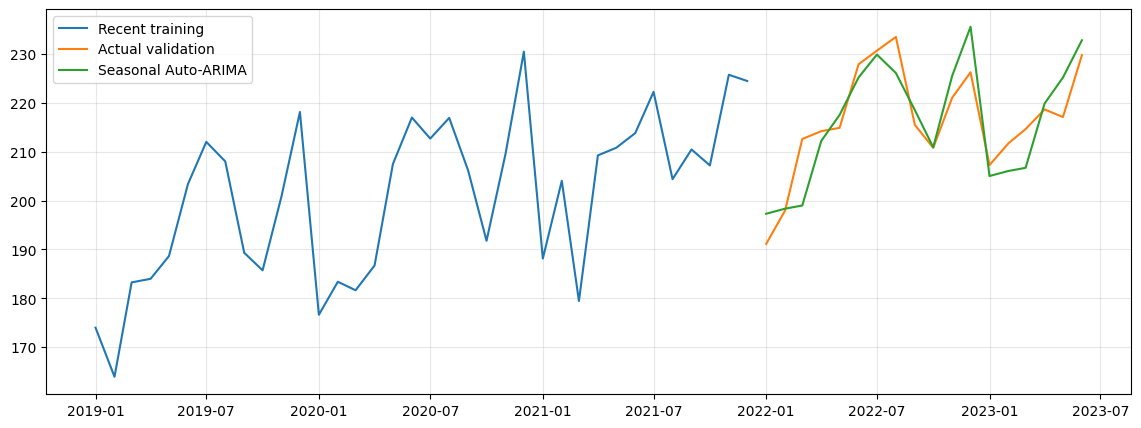

In [10]:
seasonal_pred = pd.Series(
    seasonal_model.predict(n_periods=len(validation)),
    index=validation.index
)
plt.figure(figsize=(14,5))
plt.plot(y_train.tail(36), label="Recent training")
plt.plot(y_val, label="Actual validation")
plt.plot(seasonal_pred, label="Seasonal Auto-ARIMA")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 7. Evaluate validation forecasts

MAE and RMSE are in target units. WMAPE is the sum of absolute errors divided by total absolute actual demand. Bias is mean forecast minus actual; positive bias indicates over-forecasting.

In [11]:
def metrics(actual, pred):
    actual = pd.Series(actual).astype(float)
    pred = pd.Series(pred, index=actual.index).astype(float)
    err = pred - actual
    return {
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "WMAPE": np.abs(err).sum()/np.abs(actual).sum(),
        "Bias (forecast - actual)": err.mean()
    }

validation_results = pd.DataFrame({
    "Non-seasonal Auto-ARIMA": metrics(y_val, nonseasonal_pred),
    "Seasonal Auto-ARIMA": metrics(y_val, seasonal_pred)
}).T
validation_results

,MAE,RMSE,WMAPE,Bias (forecast - actual)
Non-seasonal Auto-ARIMA,8.52264,11.340235,0.039379,-2.787757
Seasonal Auto-ARIMA,4.48662,5.719063,0.020731,-0.217080


## 8. Residual diagnostics

Residuals are observed values minus fitted values. Inspect their time plot, distribution, and ACF. The Ljung-Box test checks whether a group of residual autocorrelations is jointly different from zero; a small p-value suggests remaining autocorrelation. It is only one diagnostic.

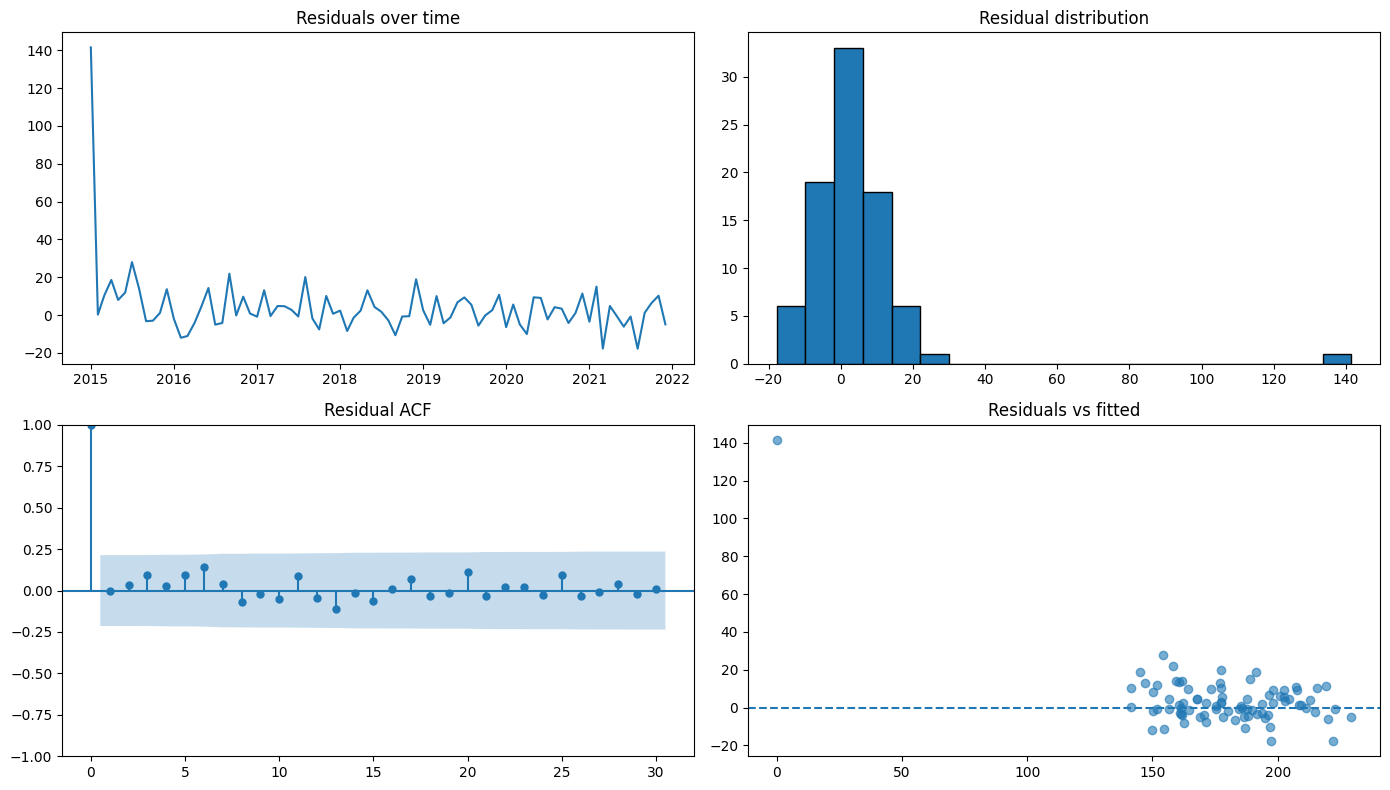

,lb_stat,lb_pvalue
12,5.335524,0.945823
24,9.415468,0.996567


In [12]:
resid = pd.Series(seasonal_model.resid()).dropna()
fig, axes = plt.subplots(2,2,figsize=(14,8))
axes[0,0].plot(resid); axes[0,0].set_title("Residuals over time")
axes[0,1].hist(resid,bins=20,edgecolor="black"); axes[0,1].set_title("Residual distribution")
plot_acf(resid,lags=30,ax=axes[1,0]); axes[1,0].set_title("Residual ACF")
axes[1,1].plot(seasonal_model.predict_in_sample(), resid, "o", alpha=.6)
axes[1,1].axhline(0,ls="--"); axes[1,1].set_title("Residuals vs fitted")
plt.tight_layout(); plt.show()
acorr_ljungbox(resid, lags=[12,24], return_df=True)

## 9. Refit on train + validation and evaluate on test

After selecting a model using validation, refit on the combined training and validation data. Evaluate once on the untouched test period. This example reruns seasonal Auto-ARIMA on the expanded history.

In [13]:
train_val = pd.concat([train, validation])
final_model = auto_arima(
    train_val.demand, seasonal=True, m=12,
    start_p=0, start_q=0, max_p=3, max_q=3,
    start_P=0, start_Q=0, max_P=2, max_Q=2,
    d=None, D=None, max_d=2, max_D=1,
    information_criterion="aic", stepwise=True,
    trace=False, error_action="ignore",
    suppress_warnings=True, with_intercept="auto"
)
test_pred = pd.Series(final_model.predict(n_periods=len(test)), index=test.index)
print("Final order:", final_model.order)
print("Final seasonal order:", final_model.seasonal_order)
pd.Series(metrics(y_test, test_pred))

Final order: (0, 1, 1)
Final seasonal order: (2, 0, 0, 12)


MAE                          9.122855
RMSE                        11.148912
WMAPE                        0.038808
Bias (forecast - actual)    -7.392152
dtype: float64

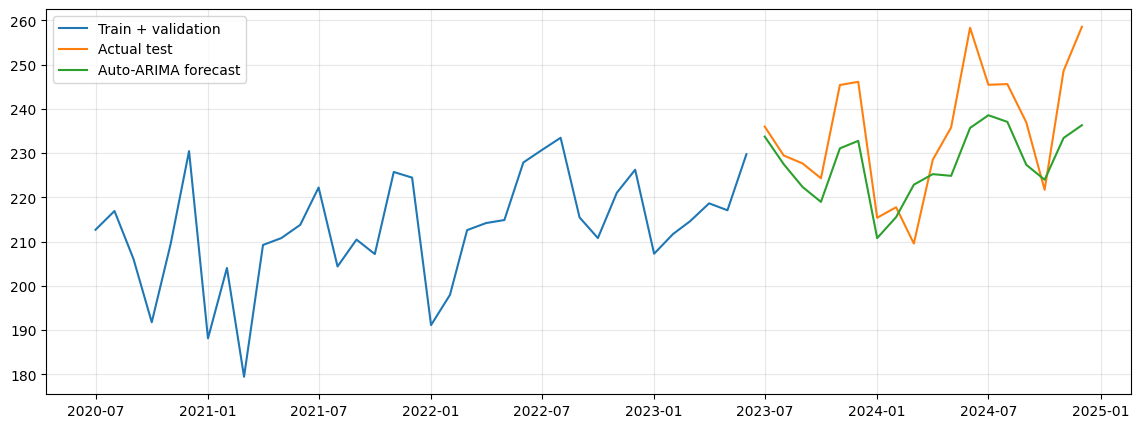

In [14]:
plt.figure(figsize=(14,5))
plt.plot(train_val.demand.tail(36), label="Train + validation")
plt.plot(y_test, label="Actual test")
plt.plot(test_pred, label="Auto-ARIMA forecast")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 10. Forecast the next 12 months

The confidence interval represents uncertainty under the fitted model assumptions. It does not account for every possible source of uncertainty, such as structural breaks or unexpected business events.

In [15]:
future_values, intervals = final_model.predict(
    n_periods=12, return_conf_int=True, alpha=0.05
)
future_dates = pd.date_range(df.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
future = pd.Series(future_values, index=future_dates, name="Forecast")
intervals = pd.DataFrame(intervals, index=future_dates, columns=["Lower 95%", "Upper 95%"])
pd.concat([future, intervals], axis=1).round(2)

,Forecast,Lower 95%,Upper 95%
2025-01-01,NaN,217.89,249.60
2025-02-01,NaN,211.56,243.49
2025-03-01,NaN,206.27,238.42
2025-04-01,NaN,202.81,235.17
2025-05-01,NaN,214.80,247.37
2025-06-01,NaN,216.39,249.18
2025-07-01,NaN,194.30,227.30
2025-08-01,NaN,198.95,232.16
2025-09-01,NaN,206.16,239.59
2025-10-01,NaN,208.44,242.07


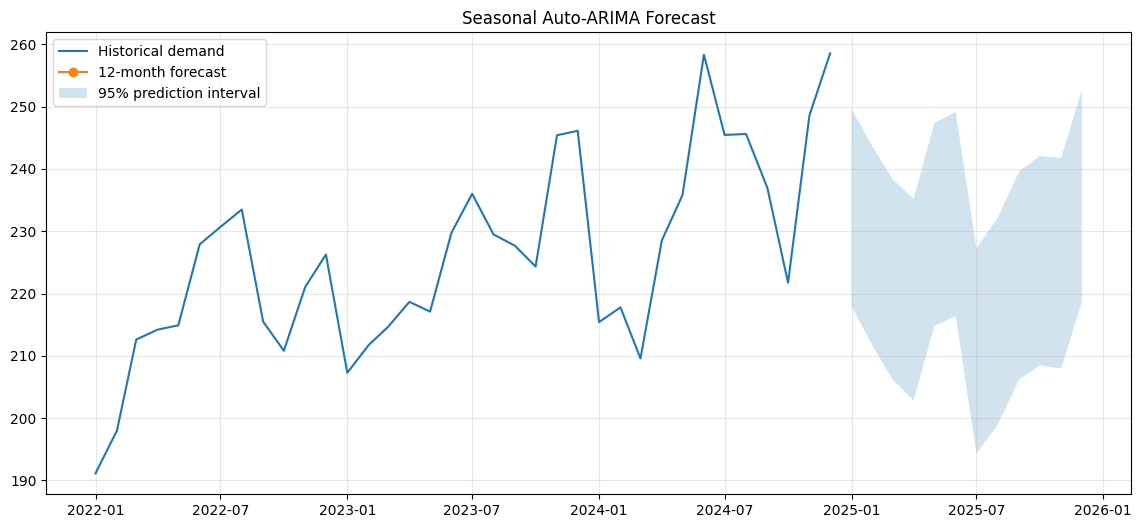

In [16]:
plt.figure(figsize=(14,6))
plt.plot(df.demand.tail(36), label="Historical demand")
plt.plot(future, marker="o", label="12-month forecast")
plt.fill_between(intervals.index, intervals.iloc[:,0], intervals.iloc[:,1], alpha=.2, label="95% prediction interval")
plt.legend(); plt.grid(True, alpha=.3); plt.title("Seasonal Auto-ARIMA Forecast"); plt.show()

## 11. Important `auto_arima()` parameters

| Parameter | Purpose |
|---|---|
| `seasonal` | Enables seasonal search |
| `m` | Seasonal cycle length |
| `start_p`, `start_q` | Starting non-seasonal AR and MA orders |
| `max_p`, `max_q` | Maximum non-seasonal AR and MA orders |
| `start_P`, `start_Q` | Starting seasonal AR and MA orders |
| `max_P`, `max_Q` | Maximum seasonal AR and MA orders |
| `d`, `D` | Non-seasonal and seasonal differencing orders; `None` permits automatic selection |
| `max_d`, `max_D` | Maximum differencing orders considered |
| `information_criterion` | Criterion such as AIC or BIC |
| `stepwise` | Uses stepwise search when enabled |
| `trace` | Prints search progress |
| `error_action` | Controls handling of candidate fitting errors |
| `with_intercept` | Controls intercept/drift inclusion, depending on model configuration |

Supported options and defaults can vary by `pmdarima` version; consult the installed version's documentation.

## 12. How the search works

1. Receive the series and search configuration.
2. Assess differencing needs using stationarity and seasonal tests.
3. Define candidate orders within configured bounds.
4. Fit candidate models.
5. Rank candidates using the selected information criterion.
6. Return the selected fitted model.

With `stepwise=True`, the algorithm explores nearby candidate configurations rather than fitting every possible combination. This can be faster, but is not an exhaustive global search. `stepwise=False` can be more computationally expensive.

## 13. Auto-ARIMA vs manual ARIMA

| Aspect | Manual ARIMA | Auto-ARIMA |
|---|---|---|
| Order selection | Analyst chooses orders | Procedure searches candidate orders |
| Effort | More experimentation | Less manual search |
| Control | Direct order choice | Search bounds, tests, criteria |
| Computation | Depends on models tried | Can be substantial for seasonal search |
| Guaranteed best forecast? | No | No |
| Validation required? | Yes | Yes |

Auto-ARIMA automates order selection, not the complete forecasting problem.

## 14. Supply-chain applications

- Seasonal retail demand forecasting.
- Statistical baselines for product-category or item-location demand.
- Automated initial ARIMA order selection across many time series.
- Benchmarking against machine-learning forecasting methods.

For highly intermittent, zero-heavy demand, standard Auto-ARIMA may not be suitable; Croston-family methods may be better candidates. For thousands of series, consider runtime, minimum history, search failures, refresh frequency, and fallback models.

## 15. Limitations and common mistakes

1. Assuming automatic means optimal.
2. Choosing the wrong seasonal period.
3. Using too little history to estimate seasonal behaviour.
4. Ignoring residual diagnostics.
5. Searching overly broad order ranges and incurring high computation.
6. Allowing future observations to influence model fitting or order selection.
7. Relying on one validation window; rolling-origin evaluation is often stronger.
8. Expecting Auto-ARIMA to anticipate structural breaks, product launches, or supply disruptions.
9. Assuming univariate Auto-ARIMA automatically discovers external drivers such as promotions or price.

## Key takeaway

**Auto-ARIMA automates the search for ARIMA/SARIMA model orders using a configured search strategy and selection criterion.** It reduces manual order-selection effort, but forecasts must still be validated on unseen data and checked through residual diagnostics.

### References
- [pmdarima documentation](https://alkaline-ml.com/pmdarima/)
- [auto_arima API](https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html)
- [Forecasting: Principles and Practice — ARIMA](https://otexts.com/fpp3/arima.html)